# Figure 3. Structural features evaluated by FastRNA

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
RENDERS = ROOT / "data" / "pymol" / "renders"
CROPPED = RENDERS / "cropped"
CROPPED.mkdir(parents=True, exist_ok=True)

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def letter(fig, ax, s, dx=-0.014, dy=0.004):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")

def letter_drawn(fig, ax, s, dx=-0.014, dy=0.004):
    fig.canvas.draw()
    pts = np.vstack([ln.get_xydata() for ln in ax.lines if len(ln.get_xydata())])
    x, y = ax.transData.transform((pts[:, 0].min(), pts[:, 1].max()))
    fx, fy = fig.transFigure.inverted().transform((x, y))
    fig.text(fx + dx, fy + dy, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")

def autocrop(name, pad=2, thresh=246):
    src, dst = RENDERS / name, CROPPED / name
    im = Image.open(src).convert("RGB")
    mask = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0)
    box = mask.getbbox()
    if box:
        l, t, r, b = box
        im = im.crop((max(0, l - pad), max(0, t - pad),
                      min(im.width, r + pad), min(im.height, b + pad)))
    im.save(dst)
    return dst

def show_pair(ax, name):
    ax.imshow(plt.imread(autocrop(f"{name}.png")))
    ax.set_xticks([]); ax.set_yticks([])
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)

print("renders:", ", ".join(sorted(p.stem for p in RENDERS.glob("1C_*.png"))))

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


renders: 1C_distorted_AU, 1C_distorted_GC, 1C_ideal_AU, 1C_ideal_GC


## Panel A
G·C cWW as the scorer sees it: ideal (left) and distorted (right)

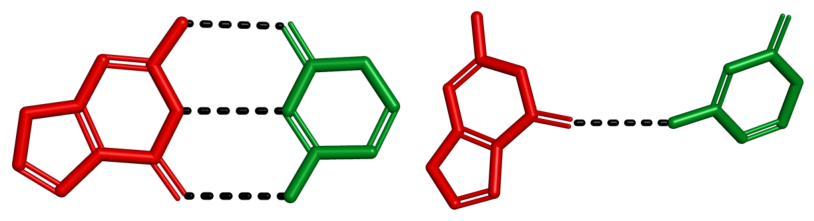

In [8]:
def draw_a(ax_top, ax_bottom):
    show_pair(ax_top, "1C_ideal_GC")
    show_pair(ax_bottom, "1C_distorted_GC")

fig, axes = plt.subplots(1, 2, figsize=(6.4, 1.8))
draw_a(*axes)
fig.tight_layout()
save(fig, "figures/main/figure3_A_GC_pairs.png")
plt.show()

## Panel B
A·U cWW: ideal (left) and distorted (right)

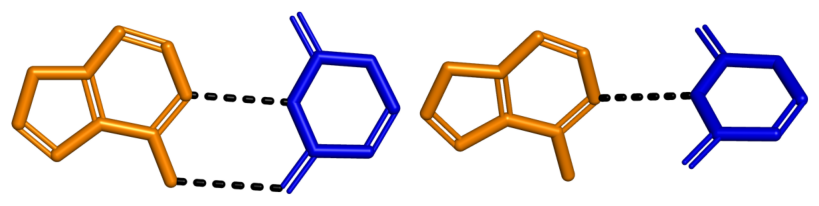

In [9]:
def draw_b(ax_top, ax_bottom):
    show_pair(ax_top, "1C_ideal_AU")
    show_pair(ax_bottom, "1C_distorted_AU")

fig, axes = plt.subplots(1, 2, figsize=(6.4, 1.8))
draw_b(*axes)
fig.tight_layout()
save(fig, "figures/main/figure3_B_AU_pairs.png")
plt.show()

## Panel C helpers

In [10]:
import json

import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import ConnectionPatch, Polygon
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

PAIR, LW_CLASS = "A-U", "cWW"
FLIP = {"shear", "stagger", "buckle"}
PROSCO_PREFERRED = 5.0
SEV_CMAP = LinearSegmentedColormap.from_list("sev", ["0.82", "#F4D03F", "#E67E22", "#C0392B"])
SEV_NORM = Normalize(0, 1)
PROSCO = _json("reference/scoring_tables/prosco_distributions.json")["prosco_distributions"]
ZTAB = _json("reference/scoring_tables/z_tables.json")

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

import sys
sys.path.insert(0, str(ROOT / "scripts" / "data_gen"))
from build_prosco_distributions import BANDWIDTH_FACTOR, canonicalize_dataframe
from _vendor.hbond_distance_policy import select_distance_rows

def scoring_kde(group="hbonds", param="distance"):
    df = pd.read_csv(data_file(f"reference/high_quality_features/{group}.csv"))
    df = canonicalize_dataframe(df, group)
    if group == "hbonds":
        df = select_distance_rows(df)
    df = df[(df["bp_type"] == PAIR) & (df["lw_class"] == LW_CLASS)]
    v = df[param].to_numpy(float)
    ok = np.isfinite(v)
    v, ids = v[ok], df["pdb_id"][ok]
    w = per_pdb_weights(ids)
    kde = gaussian_kde(v, weights=w)
    kde.set_bandwidth(kde.factor * BANDWIDTH_FACTOR)
    return v, w, kde

def per_pdb_weights(pdb_ids):
    counts = pdb_ids.value_counts()
    return np.array([1.0 / counts[p] for p in pdb_ids])

def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, w = values[order], weights[order]
    cum = np.cumsum(w)
    return float(np.interp(q * cum[-1], cum - w / 2, v))

_to_cg = lambda param, xs: xs

def _entry(table, group, param):
    c = table[group][param]
    return c.get(f"{PAIR}/{LW_CLASS}") or c.get("-".join(PAIR.split("-")[::-1]) + f"/{LW_CLASS}")

def prosco_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(PROSCO, group, param)
    lo, hi, n = c["support_lo"], c["support_hi"], c["n_bins"]
    pb = np.array(c["prosco_per_bin"], float)
    return pb[np.clip(((xs - lo) / (hi - lo) * n).astype(int), 0, n - 1)]

def zprime_at(group, param, xs_gc):
    xs = _to_cg(param, xs_gc)
    c = _entry(ZTAB, group, param)
    M, sl, su = c["M"], c["sl"], c["su"]
    return (xs - M) / np.where(xs >= M, su, sl)

def severity_at(group, param, xs_gc):
    pr, z = prosco_at(group, param, xs_gc), zprime_at(group, param, xs_gc)
    ramp = np.clip((PROSCO_PREFERRED - pr) / PROSCO_PREFERRED, 0.0, 1.0)
    return np.where(pr >= PROSCO_PREFERRED, 0.0, np.minimum(1.0, np.abs(z) / 5.0) * ramp)

def cal_panel(ax, kind, param, group, xlabel, tail=0.003, pad=0.05, include=()):
    arr, w, kde = scoring_kde(group, param)

    xs = np.linspace(arr.min(), arr.max(), 1200)
    ys = kde(xs)
    seen = xs[ys >= tail * ys.max()]
    span = seen.max() - seen.min()
    xlo, xhi = seen.min() - pad * span, seen.max() + pad * span
    if len(include):
        xlo, xhi = min(xlo, min(include) - pad * span), max(xhi, max(include) + pad * span)
    xs = np.linspace(xlo, xhi, 800)
    ys = kde(xs)
    sev = severity_at(group, param, xs)
    ymax = ys.max() * 1.10

    im = ax.imshow(SEV_CMAP(SEV_NORM(sev))[np.newaxis, :, :], extent=(xlo, xhi, 0, ymax),
                   origin="lower", aspect="auto", interpolation="bilinear", zorder=0)
    clip = Polygon(np.vstack([[xlo, 0], np.column_stack([xs, ys]), [xhi, 0]]),
                   closed=True, facecolor="none", edgecolor="none", zorder=0)
    ax.add_patch(clip)
    im.set_clip_path(clip)
    ax.plot(xs, ys, color="0.15", lw=1.3, zorder=2)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    finish(ax)
    return ax

def severity_colorbar(fig, axes, **kw):
    sm = ScalarMappable(norm=SEV_NORM, cmap=SEV_CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes, **kw)
    cb.set_label("Penalty severity", fontsize=8.5, rotation=270, va="bottom")
    cb.set_ticks([0, 0.5, 1.0])
    cb.set_ticklabels(["0", "0.5", "1"], fontsize=7.5)
    cb.outline.set_linewidth(0.8)
    return cb

## Panel C
Penalty severity across A·U cWW opening, with three example pairs

  [canonicalize/pairs] swapped 141,369 rows into canonical orientation


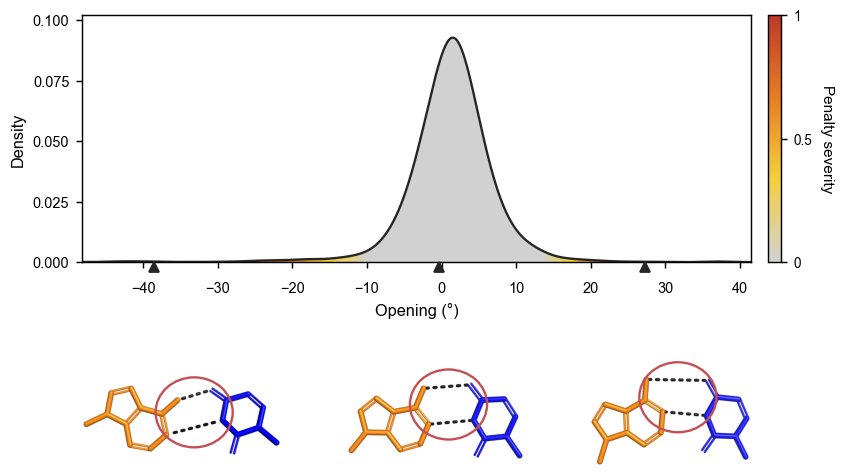

In [11]:
from matplotlib.transforms import offset_copy

EXAMPLES = [("3C_open_closed", -38.58), ("3C_open_ideal", -0.42), ("3C_open_open", 27.32)]

def tight_crops(names, pad=8, thresh=246):
    out = []
    for n in names:
        im = Image.open(RENDERS / f"{n}.png").convert("RGB")
        l, t_, r, b_ = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0).getbbox()
        dst = RENDERS / "cropped" / f"{n}_tight.png"
        dst.parent.mkdir(exist_ok=True)
        im.crop((max(0, l - pad), max(0, t_ - pad), min(im.width, r + pad),
                 min(im.height, b_ + pad))).save(dst)
        out.append(dst)
    return out


FOCUS_RED = "#C44E52"
RINGED = {"3C_open_closed", "3C_open_ideal", "3C_open_open"}


def dash_box(path):
    rgb = np.asarray(Image.open(path).convert("RGB")).astype(int)
    dark_grey = (rgb.max(axis=2) < 90) & (rgb.max(axis=2) - rgb.min(axis=2) < 30)
    ys, xs = np.nonzero(dark_grey)
    return xs.min(), xs.max(), ys.min(), ys.max()


def focus_ring(ax_i, box, size):
    from matplotlib.patches import Ellipse
    x0, x1, y0, y1 = box
    ax_i.add_patch(Ellipse(((x0 + x1) / 2, (y0 + y1) / 2), *size, fill=False,
                           ec=FOCUS_RED, lw=1.3, clip_on=False, zorder=5))


def draw_c(fig, ax, band_y0, band_h):
    cal_panel(ax, "pairs", "opening", "pairs", "Opening (°)", include=[d for _, d in EXAMPLES])
    ax.tick_params(axis="x", pad=7)
    W, H = fig.get_size_inches()
    box = ax.get_position()
    crops = tight_crops([n for n, _ in EXAMPLES])
    px = [Image.open(p).size for p in crops]
    scale = band_h * H / max(h for _, h in px)
    scale = min(scale, 0.8 * box.width * W / sum(w for w, _ in px))
    widths = [w * scale / W for w, _ in px]
    heights = [h * scale / H for _, h in px]
    gap = (box.width - sum(widths)) / (len(EXAMPLES) - 1)
    boxes = {n: dash_box(p) for (n, _), p in zip(EXAMPLES, crops) if n in RINGED}
    ring = (1.35 * max(b[1] - b[0] for b in boxes.values()),
            1.6 * max(b[3] - b[2] for b in boxes.values()))
    x = box.x0
    for (name, d), iw, ih, path in zip(EXAMPLES, widths, heights, crops):
        ax_i = fig.add_axes([x, band_y0 + (band_h - ih) / 2, iw, ih])
        x += iw + gap
        ax_i.imshow(plt.imread(path))
        ax_i.set_axis_off()
        if name in RINGED:
            focus_ring(ax_i, boxes[name], ring)
        ms = 5
        ax.plot([d], [0], marker="^", ms=ms, color="0.15", clip_on=False, zorder=5,
                transform=offset_copy(ax.transData, fig=fig, y=-ms / 2, units="points"))
    return ax

fig = plt.figure(figsize=(6.6, 3.8))
ax = fig.add_axes([0.1, 0.45, 0.78, 0.5])
draw_c(fig, ax, 0.02, 0.22)
cb = severity_colorbar(fig, [ax], cax=fig.add_axes([0.9, 0.45, 0.015, 0.5]))
save(fig, "figures/main/figure3_C_opening_examples.png")
plt.show()

## Combined figure


  [canonicalize/pairs] swapped 141,369 rows into canonical orientation
saved 7.31 x 5.13 in; at 6.73 in wide the smallest text prints at 7.03 pt, height 4.73 in


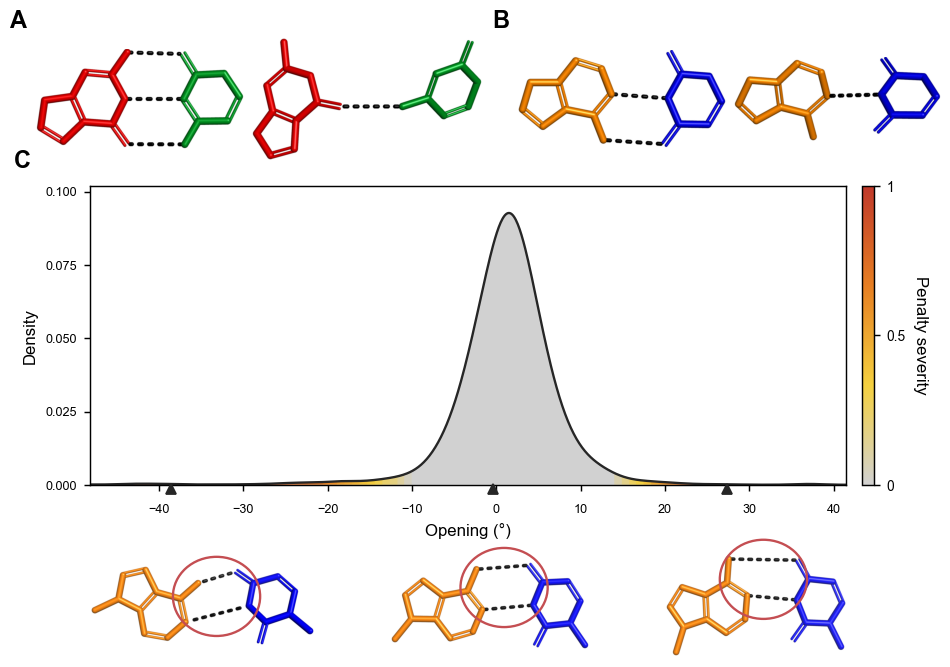

In [12]:
FIG_W, FIG_H = 7.2, 8.0
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]

X_0, X_END, PAIR_GAP, PANEL_GAP = 0.22, FIG_W - 0.03, 0.06, 0.28
names = ("1C_ideal_GC", "1C_distorted_GC", "1C_ideal_AU", "1C_distorted_AU")
crop_px = {n: Image.open(autocrop(f"{n}.png")).size for n in names}
SCALE = (X_END - X_0 - 2 * PAIR_GAP - PANEL_GAP) / sum(w for w, h in crop_px.values())

TOP_1 = 0.3
sizes = {n: tuple(v * SCALE for v in crop_px[n]) for n in names}
ROW_H = max(h for _, h in sizes.values())
xs, x = [], X_0
for n, gap in zip(names, (PAIR_GAP, PANEL_GAP, PAIR_GAP, 0)):
    xs.append(x)
    x += sizes[n][0] + gap
X_A, X_B = xs[0], xs[2]
ax_a1, ax_a2, ax_b1, ax_b2 = (
    fig.add_axes(inch(x0, TOP_1 + (ROW_H - sizes[n][1]) / 2, *sizes[n]))
    for x0, n in zip(xs, names))
draw_a(ax_a1, ax_a2)
draw_b(ax_b1, ax_b2)

C_TOP, C_H = TOP_1 + ROW_H + 0.20, 2.3
C_X = 0.63
C_W = FIG_W - C_X - 0.75
BAND_TOP, BAND_H = C_TOP + C_H + 0.27, 1.315
ax_c = fig.add_axes(inch(C_X, C_TOP, C_W, C_H))
band = inch(C_X, BAND_TOP, C_W, BAND_H)
draw_c(fig, ax_c, band[1], band[3])
cax = fig.add_axes(inch(C_X + C_W + 0.12, C_TOP, 0.09, C_H))
cb = severity_colorbar(fig, [ax_c], cax=cax)
cb.set_ticklabels(["0", "0.5", "1"])

for s, x in (("A", X_A), ("B", X_B)):
    fig.text((x - 0.2) / FIG_W, 1 - TOP_1 / FIG_H + 0.005, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")
fig.text(0.05 / FIG_W, 1 - (C_TOP - 0.1) / FIG_H, "C", fontsize=12, fontweight="bold",
         ha="left", va="bottom")

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
enlarge_axis_labels(fig)

def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt, height {(bb.height + 2 * pad) / shrink:.2f} in")


_ensure_print_pt(fig)

save(fig, "figures/main/figure3.png")
plt.show()